# Multi-Task AST-Based Deep Knowledge Tracing for Programming Education Using Project CodeNet

## Abstract

Deep Knowledge Tracing (DKT) is a widely used approach for modeling student learning behavior by analyzing sequential educational interactions. Traditional DKT models primarily rely on correctness information and often fail to capture the rich programming knowledge embedded within source code submissions. In programming education, student code contains valuable information regarding the concepts and problem-solving strategies employed during learning. This study proposes a Multi-Task AST-Based Deep Knowledge Tracing framework that automatically extracts programming skills from source code using Abstract Syntax Trees (ASTs). The extracted skills are incorporated into a Long Short-Term Memory (LSTM)-based architecture that jointly predicts future submission correctness and programming skill mastery. The proposed framework is evaluated using the Project CodeNet dataset and employs leakage-free five-fold user-level cross-validation to ensure robust evaluation. Model performance is assessed using Accuracy, Area Under the ROC Curve (AUC), Precision, Recall, and F1-score. Furthermore, per-skill performance analysis is conducted to investigate the model's ability to capture different programming competencies. The results demonstrate the effectiveness of combining AST-derived programming skills with deep knowledge tracing and highlight the potential of multi-task learning for personalized programming education and intelligent tutoring systems.

---

# 1. Introduction

The increasing popularity of online programming education platforms has generated large amounts of student interaction data. Understanding how students acquire programming knowledge over time is essential for developing intelligent tutoring systems, adaptive learning environments, and personalized educational interventions. Knowledge Tracing (KT) aims to model a learner’s evolving knowledge state by analyzing historical learning interactions and predicting future performance.

Deep Knowledge Tracing (DKT), introduced using recurrent neural networks, has demonstrated superior performance compared to traditional probabilistic approaches. However, most DKT models utilize only binary correctness information and ignore the detailed programming knowledge contained within source code submissions. Such information can provide valuable insights into the specific concepts and skills used by learners when solving programming problems.

In programming education, source code naturally reflects the learner's understanding of programming concepts such as loops, conditional statements, recursion, data structures, and algorithms. By analyzing source code through Abstract Syntax Trees (ASTs), it becomes possible to automatically identify these programming skills without requiring manual annotation.

This study proposes a Multi-Task AST-Based Deep Knowledge Tracing framework that integrates AST-derived programming skills into a deep learning architecture. The model simultaneously predicts future submission correctness and future skill mastery, allowing more comprehensive modeling of student learning behavior.

---

# 2. Research Problem

Traditional knowledge tracing models primarily focus on predicting whether a student will answer a future question correctly. While effective for general educational settings, such approaches provide limited insight into the specific programming skills mastered by learners.

Furthermore, most existing models treat programming submissions as simple binary outcomes and fail to utilize the rich structural information available in source code. Consequently, important information regarding student understanding of programming concepts remains unexploited.

Therefore, the primary research problem addressed in this study is:

**How can source code analysis and multi-task learning be combined to improve knowledge tracing and programming skill assessment in programming education?**

---

# 3. Research Objectives

The objectives of this study are:

1. To automatically extract programming skills from Python source code using AST analysis.
2. To construct sequential student interaction histories from programming submissions.
3. To develop a multi-task Deep Knowledge Tracing framework.
4. To predict future correctness of programming submissions.
5. To predict future programming skill mastery.
6. To evaluate model performance using leakage-free user-level cross-validation.
7. To investigate skill-specific learning patterns through per-skill analysis.

---

# 4. Research Contributions

The major contributions of this work include:

* Automatic extraction of programming skills using Abstract Syntax Trees.
* Development of a multi-task DKT architecture for simultaneous correctness and skill prediction.
* User-level cross-validation that prevents data leakage.
* Fine-grained programming skill analysis.
* Application and evaluation on the large-scale Project CodeNet dataset.
* Comprehensive assessment using multiple evaluation metrics.

---

# 5. Dataset Description

## 5.1 Project CodeNet

Project CodeNet is a large-scale dataset consisting of millions of programming submissions collected from competitive programming platforms. The dataset contains source code, submission outcomes, user information, and problem metadata across multiple programming languages.

For this study, only Python submissions are considered due to the availability of Python AST parsing tools and the popularity of Python in programming education.

Each submission contains:

* User identifier
* Problem identifier
* Source code file
* Submission timestamp
* Submission status

The submission status is transformed into a binary correctness label:

* Accepted = 1
* Non-Accepted = 0

To ensure reliable knowledge tracing, only students with at least twenty programming interactions are retained.

---

# 6. Data Preprocessing

Data preprocessing consists of several stages:

### Language Filtering

Only Python submissions are retained from the original Project CodeNet dataset.

### Correctness Label Generation

Submission outcomes are converted into binary labels indicating whether a solution was accepted.

### Timestamp Processing

Submission dates are converted into numerical timestamps to preserve temporal ordering.

### Active User Filtering

Students with fewer than twenty interactions are removed to ensure sufficient learning history for knowledge tracing.

### Skill Extraction

Each source code submission is analyzed using AST parsing to identify programming skills used within the solution.

---

# 7. AST-Based Programming Skill Extraction

## 7.1 Motivation

Programming knowledge consists of multiple concepts that cannot be effectively captured using correctness information alone. To address this limitation, source code is analyzed using Abstract Syntax Trees.

An AST represents source code as a hierarchical tree structure, enabling identification of programming constructs independently of coding style.

## 7.2 Extracted Skills

| Skill        | Description                        |
| ------------ | ---------------------------------- |
| if_else      | Conditional statements             |
| loops        | For and While loops                |
| functions    | Function definitions               |
| recursion    | Recursive function calls           |
| arrays_lists | List operations                    |
| dictionaries | Dictionary structures              |
| strings      | String manipulation                |
| algorithms   | Sorting and algorithmic operations |
| basic_syntax | General syntax constructs          |

These skills serve as knowledge components within the knowledge tracing framework.

## 7.3 AST Traversal Strategy

A custom AST visitor traverses each parsed source code tree and identifies relevant programming constructs. Specific node types are mapped to predefined programming skills. If no predefined skill is detected, the submission is assigned the basic_syntax skill.

This process enables automatic generation of skill labels without manual annotation.

---

# 8. Student Interaction Representation

Each student interaction is represented as:

(User ID, Timestamp, Correctness, Skills)

where:

* User ID identifies the learner.
* Timestamp preserves chronological ordering.
* Correctness indicates submission success.
* Skills represent programming concepts extracted from source code.

Interactions are sorted chronologically before sequence generation.

---

# 9. Multi-Hot Skill Encoding

To represent student interactions numerically, a multi-hot encoding scheme is adopted.

For each skill:

* The first half of the vector represents correctly demonstrated skills.
* The second half represents incorrectly demonstrated skills.

This encoding captures both skill usage and performance information simultaneously.

If there are K skills, the resulting interaction vector has a dimension of 2K.

---

# 10. Sequence Construction

Knowledge tracing requires sequential learning histories.

For each student:

1. Interactions are sorted by timestamp.
2. Input-target pairs are generated.
3. Sliding windows are used to create fixed-length sequences.

The study uses:

* Maximum sequence length = 50
* Sliding window stride = 25

The sliding-window strategy increases the number of training samples while preserving temporal information.

---

# 11. Multi-Task Deep Knowledge Tracing Model

## 11.1 Model Overview

The proposed model is based on a Long Short-Term Memory (LSTM) architecture.

The network receives encoded interaction sequences and learns temporal patterns within student learning histories.

The model simultaneously performs two tasks:

1. Correctness Prediction
2. Skill Mastery Prediction

This multi-task formulation enables shared learning representations that improve generalization.

## 11.2 LSTM Layer

The LSTM serves as the backbone of the model and captures long-term dependencies within student interaction sequences.

Model configuration:

* Hidden size: 128
* Number of layers: 2
* Dropout: 0.3

## 11.3 Correctness Prediction Head

The correctness prediction head estimates the probability that a student will correctly solve the next programming task.

## 11.4 Skill Prediction Head

The skill prediction head estimates future programming skill mastery states.

The shared hidden representation learned by the LSTM is utilized by both prediction heads.

---

# 12. Loss Function

The model optimizes a combined multi-task objective:

Loss = Correctness Loss + 0.3 × Skill Loss

Binary Cross Entropy with Logits Loss is used for both tasks.

The correctness prediction task serves as the primary objective, while skill prediction acts as an auxiliary task that regularizes the learned representation and improves knowledge state estimation.

---

# 13. Cross-Validation Strategy

To ensure reliable evaluation, five-fold user-level cross-validation is employed.

Unlike interaction-level splitting, user-level splitting guarantees that interactions from the same student never appear in both training and validation sets.

This strategy eliminates data leakage and provides a more realistic assessment of model performance on unseen students.

---

# 14. Evaluation Metrics

The proposed framework is evaluated using the following metrics:

### Accuracy

Measures the proportion of correctly classified interactions.

### Area Under the ROC Curve (AUC)

Measures the model’s ability to distinguish between correct and incorrect outcomes.

### Precision

Measures the proportion of positive predictions that are correct.

### Recall

Measures the proportion of actual positive cases identified by the model.

### F1-Score

Represents the harmonic mean of Precision and Recall.

These metrics provide a comprehensive assessment of predictive performance.

---

# 15. Training Configuration

The model is trained using the following hyperparameters:

| Parameter               | Value |
| ----------------------- | ----- |
| Optimizer               | Adam  |
| Learning Rate           | 0.001 |
| Hidden Size             | 128   |
| Number of Layers        | 2     |
| Dropout                 | 0.30  |
| Batch Size              | 32    |
| Epochs                  | 30    |
| Early Stopping Patience | 5     |
| Sequence Length         | 50    |
| Stride                  | 25    |

Gradient clipping is applied to improve training stability.

---

# 16. Experimental Workflow

The complete experimental workflow is summarized below:

Project CodeNet Dataset

↓

Python Submission Filtering

↓

AST Parsing

↓

Programming Skill Extraction

↓

Interaction Construction

↓

Sequence Generation

↓

Multi-Hot Encoding

↓

Multi-Task DKT Model

↓

5-Fold User-Level Cross Validation

↓

Performance Evaluation

---

# 17. Results and Discussion

The average Accuracy, AUC, Precision, Recall, and F1-score are reported to assess the effectiveness of the proposed approach.

In addition, per-skill performance analysis is conducted to investigate which programming concepts are most accurately modeled by the framework.


---

# 18. Conclusion

This study presented a Multi-Task AST-Based Deep Knowledge Tracing framework for programming education. The proposed approach automatically extracts programming skills from source code using Abstract Syntax Trees and integrates them into a multi-task LSTM-based knowledge tracing model. By jointly predicting future correctness and programming skill mastery, the framework provides a richer representation of student learning behavior than traditional correctness-only approaches.

The use of user-level cross-validation ensures a leakage-free evaluation, while per-skill analysis enables detailed investigation of programming competencies. The results demonstrate the potential of combining source code analysis and deep learning for personalized programming education, intelligent tutoring systems, and learning analytics. Future work may explore transformer-based architectures, larger skill taxonomies, and additional programming languages to further improve knowledge tracing performance.


In [2]:
# ==========================================================
#
# MULTI-TASK AST-BASED PROGRAMMING DKT
# WITH:
# ✔ 5-FOLD USER-LEVEL CROSS VALIDATION
# ✔ LEAKAGE-FREE SPLIT
# ✔ ACCURACY
# ✔ AUC
# ✔ PRECISION
# ✔ RECALL
# ✔ F1-SCORE
# ✔ PER-SKILL METRICS
# ✔ KNOWLEDGE STATE ANALYSIS
# ==========================================================

import os
import ast
import random
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)

from sklearn.model_selection import KFold

from tqdm import tqdm

warnings.filterwarnings("ignore")

sns.set(style="whitegrid")

# ==========================================================
# RANDOM SEED
# ==========================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# ==========================================================
# DEVICE
# ==========================================================

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("=" * 70)
print("MULTI-TASK AST-BASED PROGRAMMING DKT")
print("=" * 70)

print(f" Device: {device}")

# ==========================================================
# DATASET PATH
# ==========================================================

# Set the CODENET_PATH environment variable, or replace the default below
DATASET_PATH = os.environ.get("CODENET_PATH", r"path/to/Project_CodeNet")

# ==========================================================
# SKILLS
# ==========================================================

SKILLS = [

    "if_else",
    "loops",
    "functions",
    "recursion",
    "arrays_lists",
    "dictionaries",
    "strings",
    "algorithms",
    "basic_syntax"

]

# ==========================================================
# AST SKILL EXTRACTOR
# ==========================================================

class SkillExtractor(ast.NodeVisitor):

    def __init__(self):

        self.skills = set()
        self.current_function = None

    def visit_If(self, node):

        self.skills.add("if_else")
        self.generic_visit(node)

    def visit_For(self, node):

        self.skills.add("loops")
        self.generic_visit(node)

    def visit_While(self, node):

        self.skills.add("loops")
        self.generic_visit(node)

    def visit_FunctionDef(self, node):

        self.skills.add("functions")

        previous = self.current_function
        self.current_function = node.name

        self.generic_visit(node)

        self.current_function = previous

    def visit_Call(self, node):

        # recursion
        if isinstance(node.func, ast.Name):

            if node.func.id == self.current_function:

                self.skills.add("recursion")

        # methods
        if isinstance(node.func, ast.Attribute):

            if node.func.attr in [
                "append",
                "pop",
                "extend"
            ]:

                self.skills.add("arrays_lists")

            if node.func.attr in [
                "split",
                "strip",
                "replace",
                "join"
            ]:

                self.skills.add("strings")

            if node.func.attr in [
                "sort"
            ]:

                self.skills.add("algorithms")

        self.generic_visit(node)

    def visit_List(self, node):

        self.skills.add("arrays_lists")
        self.generic_visit(node)

    def visit_Dict(self, node):

        self.skills.add("dictionaries")
        self.generic_visit(node)

# ==========================================================
# LOAD DATASET
# ==========================================================

print("\n Loading dataset...")

metadata_path = os.path.join(
    DATASET_PATH,
    "metadata"
)

data_path = os.path.join(
    DATASET_PATH,
    "data"
)

metadata_files = [

    f for f in os.listdir(metadata_path)

    if f.endswith(".csv")
    and f != "problem_list.csv"

]

MAX_PROBLEMS = 4053

# ==========================================================
# Shuffle metadata before truncation
# ==========================================================
random.shuffle(metadata_files)
metadata_files = metadata_files[:MAX_PROBLEMS]

print(f"Problems loaded: {len(metadata_files)}")

all_rows = []

# ==========================================================
# READ DATA
# ==========================================================

for file_name in tqdm(
    metadata_files,
    desc="Processing Problems"
):

    try:

        problem_id = file_name.replace(
            ".csv",
            ""
        )

        metadata_file = os.path.join(
            metadata_path,
            file_name
        )

        df_temp = pd.read_csv(metadata_file)

        # --------------------------------------------------
        # PYTHON ONLY
        # --------------------------------------------------

        language_col = None

        for col in df_temp.columns:

            if "language" in col.lower():

                language_col = col
                break

        if language_col is None:
            continue

        df_temp = df_temp[
            df_temp[language_col]
            .astype(str)
            .str.contains(
                "python",
                case=False,
                na=False
            )
        ]

        if len(df_temp) == 0:
            continue

        # --------------------------------------------------
        # CORRECTNESS
        # --------------------------------------------------

        df_temp["correct"] = (
            df_temp["status"] == "Accepted"
        ).astype(int)

        # --------------------------------------------------
        # TIMESTAMP
        # --------------------------------------------------

        if "date" in df_temp.columns:

            df_temp["timestamp"] = pd.to_datetime(
                df_temp["date"],
                errors="coerce"
            )

            df_temp["timestamp"] = (
                df_temp["timestamp"]
                .astype(np.int64)
                // 10**9
            )

        else:

            df_temp["timestamp"] = np.arange(len(df_temp))

        # --------------------------------------------------
        # READ CODE
        # --------------------------------------------------

        for _, row in df_temp.iterrows():

            try:

                submission_id = str(
                    row["submission_id"]
                )

                code_file = os.path.join(

                    data_path,
                    problem_id,
                    "Python",
                    f"{submission_id}.py"

                )

                if not os.path.exists(code_file):
                    continue

                with open(
                    code_file,
                    "r",
                    encoding="utf-8",
                    errors="ignore"
                ) as f:

                    code = f.read()

                try:

                    tree = ast.parse(code)

                    extractor = SkillExtractor()

                    extractor.visit(tree)

                    skills = list(extractor.skills)

                    if len(skills) == 0:
                        skills = ["basic_syntax"]

                except:

                    skills = ["basic_syntax"]

                all_rows.append({

                    "user_id":
                    row["user_id"],

                    "timestamp":
                    row["timestamp"],

                    "correct":
                    row["correct"],

                    "skills":
                    skills

                })

            except:
                continue

    except:
        continue

# ==========================================================
# FINAL DATAFRAME
# ==========================================================

df = pd.DataFrame(all_rows)

print(f"\n Interactions: {len(df):,}")

# ==========================================================
# FILTER ACTIVE USERS
# ==========================================================

user_counts = df.groupby(
    "user_id"
).size()

active_users = user_counts[
    user_counts >= 20
].index

df = df[
    df["user_id"].isin(active_users)
]

print(f" Students: {df['user_id'].nunique():,}")

# ==========================================================
# SKILL MAPPING
# ==========================================================

skill_to_idx = {

    skill: idx

    for idx, skill in enumerate(SKILLS)

}

num_skills = len(skill_to_idx)

# ==========================================================
#  Build sequences with sliding windows
# ==========================================================

def build_sequences(
    dataframe,
    max_seq_len=50,
    stride=25
):

    sequences = []
    targets = []
    skill_targets = []

    grouped = dataframe.groupby("user_id")

    for _, group in grouped:

        group = group.sort_values(
            "timestamp"
        )

        interactions = []

        for _, row in group.iterrows():

            skills = row["skills"]
            correct = row["correct"]

            multi_hot = torch.zeros(
                2 * num_skills
            )

            skill_vector = torch.zeros(
                num_skills
            )

            for skill in skills:

                if skill not in skill_to_idx:
                    continue

                idx = skill_to_idx[skill]

                skill_vector[idx] = 1

                if correct == 1:

                    multi_hot[idx] = 1

                else:

                    multi_hot[num_skills + idx] = 1

            interactions.append(
                (
                    multi_hot,
                    correct,
                    skill_vector
                )
            )

        if len(interactions) < 5:
            continue

        seq_x = []
        seq_y = []
        seq_skill = []

        for i in range(len(interactions)-1):

            current_x, _, _ = interactions[i]

            next_correct = interactions[i+1][1]

            next_skill = interactions[i+1][2]

            seq_x.append(current_x)
            seq_y.append(next_correct)
            seq_skill.append(next_skill)

        # Use sliding windows with stride instead of non-overlapping segments
        for j in range(
            0,
            len(seq_x),
            stride
        ):

            x_part = seq_x[j:j+max_seq_len]
            y_part = seq_y[j:j+max_seq_len]
            s_part = seq_skill[j:j+max_seq_len]

            if len(x_part) >= 5:

                sequences.append(
                    torch.stack(x_part)
                )

                targets.append(
                    torch.tensor(
                        y_part,
                        dtype=torch.float
                    )
                )

                skill_targets.append(
                    torch.stack(s_part)
                )

    return sequences, targets, skill_targets

# ==========================================================
# DATASET
# ==========================================================

class DKTDataset(Dataset):

    def __init__(
        self,
        sequences,
        targets,
        skill_targets
    ):

        self.sequences = sequences
        self.targets = targets
        self.skill_targets = skill_targets

    def __len__(self):

        return len(self.sequences)

    def __getitem__(self, idx):

        return (

            self.sequences[idx],
            self.targets[idx],
            self.skill_targets[idx]

        )

# ==========================================================
# COLLATE FUNCTION
# ==========================================================

def collate_fn(batch):

    sequences, targets, skill_targets = zip(*batch)

    padded_sequences = nn.utils.rnn.pad_sequence(
        sequences,
        batch_first=True
    )

    padded_targets = nn.utils.rnn.pad_sequence(
        targets,
        batch_first=True,
        padding_value=-1
    )

    padded_skills = nn.utils.rnn.pad_sequence(
        skill_targets,
        batch_first=True,
        padding_value=-1
    )

    return (
        padded_sequences,
        padded_targets,
        padded_skills
    )

# ==========================================================
# MODEL
# ==========================================================

class MultiTaskDKT(nn.Module):

    def __init__(
        self,
        num_skills,
        hidden_size=128
    ):

        super().__init__()

        self.lstm = nn.LSTM(

            input_size=2 * num_skills,

            hidden_size=hidden_size,

            num_layers=2,

            batch_first=True,

            dropout=0.3

        )

        self.dropout = nn.Dropout(0.3)

        self.correct_head = nn.Sequential(

            nn.Linear(
                hidden_size,
                hidden_size
            ),

            nn.ReLU(),

            nn.Dropout(0.3),

            nn.Linear(
                hidden_size,
                1
            )

        )

        self.skill_head = nn.Sequential(

            nn.Linear(
                hidden_size,
                hidden_size
            ),

            nn.ReLU(),

            nn.Dropout(0.3),

            nn.Linear(
                hidden_size,
                num_skills
            )

        )

    def forward(self, x):

        out, _ = self.lstm(x)

        out = self.dropout(out)

        correct_logits = self.correct_head(out)

        skill_logits = self.skill_head(out)

        return (

            correct_logits.squeeze(-1),
            skill_logits

        )

# ==========================================================
# 5-FOLD USER-LEVEL CROSS VALIDATION
# ==========================================================

users = df["user_id"].unique()

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

fold_results = []

# ==========================================================
# Store per-skill metrics for all folds
# ==========================================================

all_folds_skill_metrics = []

# ==========================================================
# START FOLDS
# ==========================================================

for fold, (train_idx, val_idx) in enumerate(kf.split(users)):

    print("\n" + "=" * 70)
    print(f" FOLD {fold+1}")
    print("=" * 70)

    train_users = users[train_idx]
    val_users = users[val_idx]

    train_df = df[
        df["user_id"].isin(train_users)
    ]

    val_df = df[
        df["user_id"].isin(val_users)
    ]

    train_sequences, train_targets, train_skill_targets = build_sequences(train_df)

    val_sequences, val_targets, val_skill_targets = build_sequences(val_df)

    train_loader = DataLoader(

        DKTDataset(
            train_sequences,
            train_targets,
            train_skill_targets
        ),

        batch_size=32,
        shuffle=True,
        collate_fn=collate_fn
    )

    val_loader = DataLoader(

        DKTDataset(
            val_sequences,
            val_targets,
            val_skill_targets
        ),

        batch_size=32,
        shuffle=False,
        collate_fn=collate_fn
    )

    # ======================================================
    # MODEL INIT
    # ======================================================

    model = MultiTaskDKT(
        num_skills=num_skills
    ).to(device)

    criterion_correct = nn.BCEWithLogitsLoss()

    criterion_skill = nn.BCEWithLogitsLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=0.001,
        weight_decay=1e-4
    )

    best_auc = 0

    # ======================================================
    # TRAIN FUNCTION
    # ======================================================

    def run_epoch(loader, train=True):

        if train:
            model.train()
        else:
            model.eval()

        total_loss = 0

        all_preds = []
        all_targets = []

        for seqs, targets, skill_targets in loader:

            seqs = seqs.to(device)

            targets = targets.to(device)

            skill_targets = skill_targets.to(device)

            mask = (targets != -1)

            if train:
                optimizer.zero_grad()

            with torch.set_grad_enabled(train):

                correct_logits, skill_logits = model(seqs)

                valid_logits = correct_logits[mask]

                valid_targets = targets[mask]

                loss_correct = criterion_correct(
                    valid_logits,
                    valid_targets
                )

                skill_mask = (
                    skill_targets != -1
                )

                loss_skill = criterion_skill(

                    skill_logits[skill_mask],
                    skill_targets[skill_mask]

                )

                loss = (
                    loss_correct
                    + 0.3 * loss_skill
                )

                if train:

                    loss.backward()

                    torch.nn.utils.clip_grad_norm_(
                        model.parameters(),
                        1.0
                    )

                    optimizer.step()

            total_loss += loss.item()

            probs = torch.sigmoid(valid_logits)

            all_preds.extend(
                probs.detach()
                .cpu()
                .numpy()
            )

            all_targets.extend(
                valid_targets.detach()
                .cpu()
                .numpy()
            )

        preds_binary = (
            np.array(all_preds) > 0.5
        ).astype(int)

        acc = accuracy_score(
            all_targets,
            preds_binary
        )

        auc = roc_auc_score(
            all_targets,
            all_preds
        )

        precision = precision_score(
            all_targets,
            preds_binary
        )

        recall = recall_score(
            all_targets,
            preds_binary
        )

        f1 = f1_score(
            all_targets,
            preds_binary
        )

        return (

            total_loss / len(loader),

            acc,
            auc,
            precision,
            recall,
            f1
        )

    # ======================================================
    # TRAINING LOOP
    # ======================================================

    patience = 5
    counter = 0

    for epoch in range(30):

        train_metrics = run_epoch(
            train_loader,
            train=True
        )

        val_metrics = run_epoch(
            val_loader,
            train=False
        )

        (
            train_loss,
            train_acc,
            train_auc,
            train_precision,
            train_recall,
            train_f1
        ) = train_metrics

        (
            val_loss,
            val_acc,
            val_auc,
            val_precision,
            val_recall,
            val_f1
        ) = val_metrics

        print(

            f"Epoch {epoch+1:02d} | "

            f"Val Acc: {val_acc:.4f} | "

            f"Val AUC: {val_auc:.4f} | "

            f"Val Precision: {val_precision:.4f} | "

            f"Val Recall: {val_recall:.4f} | "

            f"Val F1: {val_f1:.4f}"

        )

        if val_auc > best_auc:

            best_auc = val_auc
            counter = 0

            torch.save(
                model.state_dict(),
                f"best_fold_{fold+1}.pt"
            )

        else:

            counter += 1

            if counter >= patience:

                print(" Early stopping")
                break

    # ======================================================
    # FINAL EVALUATION
    # ======================================================

    print("\n PER-SKILL METRICS")
    print("-" * 70)

    model.load_state_dict(
        torch.load(f"best_fold_{fold+1}.pt")
    )

    model.eval()

    skill_true = {s: [] for s in SKILLS}
    skill_pred = {s: [] for s in SKILLS}
    
    # Store metrics for this fold
    fold_skill_metrics = {}

    with torch.no_grad():

        for seqs, targets, skill_targets in val_loader:

            seqs = seqs.to(device)

            skill_targets = skill_targets.to(device)

            _, skill_logits = model(seqs)

            probs = torch.sigmoid(skill_logits)

            for i, skill in enumerate(SKILLS):

                preds = (
                    probs[:, :, i] > 0.5
                ).float()

                trues = skill_targets[:, :, i]

                mask = (trues != -1)

                if mask.sum() == 0:
                    continue

                skill_true[skill].extend(
                    trues[mask]
                    .cpu()
                    .numpy()
                )

                skill_pred[skill].extend(
                    preds[mask]
                    .cpu()
                    .numpy()
                )

    print(f"{'Skill':20s} | {'Acc':8s} | {'Precision':10s} | {'Recall':8s} | {'F1':8s}")
    print("-" * 70)

    for skill in SKILLS:

        if len(skill_true[skill]) == 0:
            continue

        acc = accuracy_score(
            skill_true[skill],
            skill_pred[skill]
        )

        precision = precision_score(
            skill_true[skill],
            skill_pred[skill],
            zero_division=0
        )

        recall = recall_score(
            skill_true[skill],
            skill_pred[skill],
            zero_division=0
        )

        f1 = f1_score(
            skill_true[skill],
            skill_pred[skill],
            zero_division=0
        )

        print(
            f"{skill:20s} | "
            f"{acc:.4f}     | "
            f"{precision:.4f}       | "
            f"{recall:.4f}    | "
            f"{f1:.4f}"
        )
        
        # Store metrics for this fold
        fold_skill_metrics[skill] = {
            'accuracy': acc,
            'precision': precision,
            'recall': recall,
            'f1': f1
        }
    
    all_folds_skill_metrics.append(fold_skill_metrics)

    fold_results.append({

        "fold": fold + 1,
        "accuracy": val_acc,
        "auc": val_auc,
        "precision": val_precision,
        "recall": val_recall,
        "f1": val_f1

    })

# ==========================================================
# FINAL CROSS-VALIDATION RESULTS
# ==========================================================

results_df = pd.DataFrame(fold_results)

print("\n" + "=" * 70)
print(" FINAL 5-FOLD RESULTS")
print("=" * 70)

print(results_df)

print("\n AVERAGE PERFORMANCE")
print("-" * 70)

print(f"Accuracy : {results_df['accuracy'].mean():.4f}")
print(f"AUC      : {results_df['auc'].mean():.4f}")
print(f"Precision: {results_df['precision'].mean():.4f}")
print(f"Recall   : {results_df['recall'].mean():.4f}")
print(f"F1-Score : {results_df['f1'].mean():.4f}")

# ==========================================================
# AVERAGE PER-SKILL METRICS ACROSS 5 FOLDS
# ==========================================================

print("\n" + "=" * 70)
print(" AVERAGE PER-SKILL METRICS (Across 5 Folds)")
print("=" * 70)
print("-" * 70)
print(f"{'Skill':20s} | {'Acc':8s} | {'Precision':10s} | {'Recall':8s} | {'F1':8s}")
print("-" * 70)

for skill in SKILLS:
    # Collect metrics for this skill across all folds
    acc_list = []
    prec_list = []
    rec_list = []
    f1_list = []
    
    for fold_metrics in all_folds_skill_metrics:
        if skill in fold_metrics:
            acc_list.append(fold_metrics[skill]['accuracy'])
            prec_list.append(fold_metrics[skill]['precision'])
            rec_list.append(fold_metrics[skill]['recall'])
            f1_list.append(fold_metrics[skill]['f1'])
    
    if acc_list:  # If we have data for this skill
        avg_acc = np.mean(acc_list)
        avg_prec = np.mean(prec_list)
        avg_rec = np.mean(rec_list)
        avg_f1 = np.mean(f1_list)
        
        print(
            f"{skill:20s} | "
            f"{avg_acc:.4f}   | "
            f"{avg_prec:.4f}     | "
            f"{avg_rec:.4f}   | "
            f"{avg_f1:.4f}"
        )

print("=" * 70)

print("\n COMPLETE MULTI-TASK PROGRAMMING DKT FINISHED!")

MULTI-TASK AST-BASED PROGRAMMING DKT
 Device: cuda

 Loading dataset...
Problems loaded: 4053


Processing Problems: 100%|██████████| 4053/4053 [1:33:37<00:00,  1.39s/it]  



 Interactions: 3,286,314
 Students: 19,049

 FOLD 1
Epoch 01 | Val Acc: 0.6399 | Val AUC: 0.6789 | Val Precision: 0.6517 | Val Recall: 0.7368 | Val F1: 0.6916
Epoch 02 | Val Acc: 0.6390 | Val AUC: 0.6787 | Val Precision: 0.6475 | Val Recall: 0.7497 | Val F1: 0.6948
Epoch 03 | Val Acc: 0.6393 | Val AUC: 0.6786 | Val Precision: 0.6481 | Val Recall: 0.7483 | Val F1: 0.6946
Epoch 04 | Val Acc: 0.6406 | Val AUC: 0.6791 | Val Precision: 0.6565 | Val Recall: 0.7222 | Val F1: 0.6878
Epoch 05 | Val Acc: 0.6403 | Val AUC: 0.6797 | Val Precision: 0.6517 | Val Recall: 0.7386 | Val F1: 0.6925
Epoch 06 | Val Acc: 0.6403 | Val AUC: 0.6797 | Val Precision: 0.6544 | Val Recall: 0.7290 | Val F1: 0.6897
Epoch 07 | Val Acc: 0.6404 | Val AUC: 0.6796 | Val Precision: 0.6560 | Val Recall: 0.7231 | Val F1: 0.6879
Epoch 08 | Val Acc: 0.6392 | Val AUC: 0.6795 | Val Precision: 0.6446 | Val Recall: 0.7619 | Val F1: 0.6984
Epoch 09 | Val Acc: 0.6398 | Val AUC: 0.6792 | Val Precision: 0.6613 | Val Recall: 0.7032 |

# Baseline Model for Comparative Evaluation: Multi-Task AST-Based Bayesian Knowledge Tracing (BKT)

## Motivation

To evaluate the effectiveness of the proposed Multi-Task AST-Based Deep Knowledge Tracing (AST-DKT) framework, a baseline model is required for comparative analysis. While the proposed model employs a deep recurrent architecture to learn complex temporal dependencies from student interaction histories, it is important to compare its performance against a well-established knowledge tracing approach.

Bayesian Knowledge Tracing (BKT) is one of the most widely used probabilistic models for student modeling and has served as a foundational method in educational data mining research. BKT estimates student mastery through probabilistic state transitions and observation models, making it a suitable baseline for evaluating the advantages of deep learning-based knowledge tracing methods.

To ensure a fair comparison, the baseline model uses the same Project CodeNet dataset, AST-based skill extraction process, programming skill taxonomy, sequence generation procedure, multi-task learning formulation, and user-level cross-validation strategy described in the previous sections. Consequently, differences in performance can be attributed primarily to the underlying knowledge tracing methodology rather than variations in preprocessing or experimental design.

---

## Bayesian Knowledge Tracing Framework

Bayesian Knowledge Tracing models student learning as a hidden state estimation problem. For each programming skill, the learner is assumed to exist in either a mastered or non-mastered state. The probability of mastery is continuously updated as new interactions are observed.

The model is characterized by four fundamental parameters:

### Initial Knowledge Probability

Represents the probability that a student has already mastered a skill before any observations are made.

### Learning Probability

Represents the probability that a student acquires mastery after an interaction.

### Guess Probability

Represents the probability that a student correctly solves a problem despite not having mastered the required skill.

### Slip Probability

Represents the probability that a student incorrectly solves a problem despite possessing mastery of the required skill.

These parameters collectively define the probabilistic learning dynamics of each student.

---

## Multi-Task Extension of BKT

Traditional BKT focuses exclusively on correctness prediction. In this study, the baseline model is extended into a multi-task framework to match the experimental setup of the proposed AST-DKT model.

The model jointly performs:

### Correctness Prediction

Estimating whether the student will correctly solve future programming tasks.

### Skill Prediction

Estimating the occurrence of programming skills in future interactions.

The incorporation of an auxiliary skill prediction task enables a more direct comparison with the proposed multi-task DKT framework.

---

## Knowledge State Updating

For each programming skill, the model maintains a latent mastery probability. During each interaction, Bayesian inference is applied to update the student's knowledge state based on observed performance.

The update process consists of:

1. Estimating the probability of observing the current response.
2. Computing posterior mastery probabilities using Bayes' theorem.
3. Applying learning transitions to update future mastery estimates.

These updates are performed sequentially throughout the student's learning history.

---

## Comparison with the Proposed AST-DKT Framework

Although both models utilize identical data representations and evaluation procedures, they differ fundamentally in how student knowledge is modeled.

The AST-DKT framework employs a Long Short-Term Memory (LSTM) network capable of learning complex temporal dependencies directly from interaction sequences. In contrast, the AST-BKT framework relies on interpretable probabilistic state transitions governed by Bayesian inference.

This comparison enables investigation of whether deep sequential representation learning provides measurable advantages over traditional probabilistic knowledge tracing for programming education.

The following section presents the implementation of the Multi-Task AST-Based Bayesian Knowledge Tracing baseline model.


In [ ]:
# ==========================================================
#
# MULTI-TASK AST-BASED PROGRAMMING BKT 
# WITH:
#  5-FOLD USER-LEVEL CROSS-VALIDATION
#  LEAKAGE-FREE SPLIT
#  ACCURACY
#  AUC
#  PRECISION
#  RECALL
#  F1-SCORE
#  PER-SKILL METRICS FOR CORRECTNESS PREDICTION
#  NEXT SKILL PREDICTION (MULTI-TASK)
#  NO INFORMATION LEAK (Uses ONLY current skills for correctness)
#  AVERAGE PER-SKILL METRICS
# ==========================================================

import os
import ast
import random
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)

from sklearn.model_selection import KFold
from tqdm import tqdm

warnings.filterwarnings("ignore")

# ==========================================================
# REPRODUCIBILITY
# ==========================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# ==========================================================
# DEVICE
# ==========================================================

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("=" * 80)
print("MULTI-TASK AST-BASED PROGRAMMING BKT")
print("=" * 80)
print(f"Device: {device}")

# ==========================================================
# PATHS
# ==========================================================

# Set the CODENET_PATH environment variable, or replace the default below
DATASET_PATH = os.environ.get("CODENET_PATH", r"path/to/Project_CodeNet")

# ==========================================================
# SKILLS
# ==========================================================

SKILLS = [

    "if_else",
    "loops",
    "functions",
    "recursion",
    "arrays_lists",
    "dictionaries",
    "strings",
    "algorithms",
    "basic_syntax"

]

skill_to_idx = {
    skill: idx
    for idx, skill in enumerate(SKILLS)
}

num_skills = len(SKILLS)

# ==========================================================
# AST SKILL EXTRACTOR
# ==========================================================

class SkillExtractor(ast.NodeVisitor):

    def __init__(self):

        self.skills = set()
        self.current_function = None

    def visit_If(self, node):

        self.skills.add("if_else")
        self.generic_visit(node)

    def visit_For(self, node):

        self.skills.add("loops")
        self.generic_visit(node)

    def visit_While(self, node):

        self.skills.add("loops")
        self.generic_visit(node)

    def visit_FunctionDef(self, node):

        self.skills.add("functions")

        previous = self.current_function
        self.current_function = node.name

        self.generic_visit(node)

        self.current_function = previous

    def visit_Call(self, node):

        if isinstance(node.func, ast.Name):

            if node.func.id == self.current_function:

                self.skills.add("recursion")

        if isinstance(node.func, ast.Attribute):

            if node.func.attr in [
                "append",
                "extend",
                "pop"
            ]:

                self.skills.add("arrays_lists")

            if node.func.attr in [
                "split",
                "replace",
                "join",
                "strip"
            ]:

                self.skills.add("strings")

            if node.func.attr in [
                "sort"
            ]:

                self.skills.add("algorithms")

        self.generic_visit(node)

    def visit_List(self, node):

        self.skills.add("arrays_lists")
        self.generic_visit(node)

    def visit_Dict(self, node):

        self.skills.add("dictionaries")
        self.generic_visit(node)

# ==========================================================
# LOAD DATASET
# ==========================================================

print("\nLoading dataset...")

metadata_path = os.path.join(DATASET_PATH, "metadata")
data_path = os.path.join(DATASET_PATH, "data")

metadata_files = [

    f for f in os.listdir(metadata_path)
    if f.endswith(".csv")
    and f != "problem_list.csv"

]

# ==========================================================
# SHUFFLE BEFORE TRUNCATION
# ==========================================================

random.shuffle(metadata_files)

MAX_PROBLEMS = 4053
metadata_files = metadata_files[:MAX_PROBLEMS]

print(f"Problems selected: {len(metadata_files)}")

all_rows = []

# ==========================================================
# READ DATA
# ==========================================================

for file_name in tqdm(
    metadata_files,
    desc="Processing Problems"
):

    try:

        problem_id = file_name.replace(".csv", "")

        metadata_file = os.path.join(
            metadata_path,
            file_name
        )

        df_temp = pd.read_csv(metadata_file)

        language_col = None

        for col in df_temp.columns:

            if "language" in col.lower():

                language_col = col
                break

        if language_col is None:
            continue

        df_temp = df_temp[
            df_temp[language_col]
            .astype(str)
            .str.contains(
                "python",
                case=False,
                na=False
            )
        ]

        if len(df_temp) == 0:
            continue

        df_temp["correct"] = (
            df_temp["status"] == "Accepted"
        ).astype(int)

        # TIMESTAMP CONVERSION
        if "date" in df_temp.columns:

            df_temp["timestamp"] = pd.to_datetime(
                df_temp["date"],
                errors="coerce"
            )

            df_temp = df_temp.dropna(
                subset=["timestamp"]
            )

            df_temp["timestamp"] = (
                df_temp["timestamp"]
                .astype("int64") // 10**9
            )

        else:

            df_temp["timestamp"] = np.arange(len(df_temp))

        for _, row in df_temp.iterrows():

            try:

                submission_id = str(row["submission_id"])

                code_file = os.path.join(

                    data_path,
                    problem_id,
                    "Python",
                    f"{submission_id}.py"

                )

                if not os.path.exists(code_file):
                    continue

                with open(
                    code_file,
                    "r",
                    encoding="utf-8",
                    errors="ignore"
                ) as f:

                    code = f.read()

                try:

                    tree = ast.parse(code)

                    extractor = SkillExtractor()
                    extractor.visit(tree)

                    skills = list(extractor.skills)

                    if len(skills) == 0:
                        skills = ["basic_syntax"]

                except Exception as e:

                    skills = ["basic_syntax"]

                all_rows.append({

                    "user_id":
                    row["user_id"],

                    "timestamp":
                    row["timestamp"],

                    "correct":
                    row["correct"],

                    "skills":
                    skills

                })

            except Exception as e:

                print(f"Submission Error: {e}")
                continue

    except Exception as e:

        print(f"Metadata Error: {e}")
        continue

# ==========================================================
# FINAL DATAFRAME
# ==========================================================

df = pd.DataFrame(all_rows)

print(f"\nInteractions: {len(df):,}")

# ==========================================================
# FILTER ACTIVE USERS
# ==========================================================

user_counts = df.groupby("user_id").size()

active_users = user_counts[
    user_counts >= 20
].index

df = df[
    df["user_id"].isin(active_users)
]

print(f"Active Students: {df['user_id'].nunique():,}")

# ==========================================================
# BUILD SEQUENCES
# ==========================================================

def build_sequences(
    dataframe,
    max_seq_len=50,
    stride=25
):

    sequences = []
    targets = []
    skill_targets = []

    grouped = dataframe.groupby("user_id")

    for _, group in grouped:

        group = group.sort_values("timestamp")

        interactions = []

        for _, row in group.iterrows():

            skills = row["skills"]
            correct = row["correct"]

            interaction_vector = torch.zeros(
                2 * num_skills
            )

            skill_vector = torch.zeros(
                num_skills
            )

            for skill in skills:

                if skill not in skill_to_idx:
                    continue

                idx = skill_to_idx[skill]

                skill_vector[idx] = 1

                if correct == 1:
                    interaction_vector[idx] = 1
                else:
                    interaction_vector[num_skills + idx] = 1

            interactions.append(

                (
                    interaction_vector,
                    correct,
                    skill_vector
                )

            )

        if len(interactions) < 5:
            continue

        seq_x = []
        seq_y = []
        seq_s = []

        for i in range(len(interactions) - 1):

            current_x, _, _ = interactions[i]

            next_correct = interactions[i + 1][1]
            next_skill = interactions[i + 1][2]

            seq_x.append(current_x)
            seq_y.append(next_correct)
            seq_s.append(next_skill)

        # SLIDING WINDOW
        for j in range(
            0,
            len(seq_x),
            stride
        ):

            x_part = seq_x[j:j + max_seq_len]
            y_part = seq_y[j:j + max_seq_len]
            s_part = seq_s[j:j + max_seq_len]

            if len(x_part) >= 5:

                sequences.append(
                    torch.stack(x_part)
                )

                targets.append(
                    torch.tensor(
                        y_part,
                        dtype=torch.float32
                    )
                )

                skill_targets.append(
                    torch.stack(s_part)
                )

    return sequences, targets, skill_targets

# ==========================================================
# DATASET
# ==========================================================

class BKTDataset(Dataset):

    def __init__(
        self,
        sequences,
        targets,
        skill_targets
    ):

        self.sequences = sequences
        self.targets = targets
        self.skill_targets = skill_targets

    def __len__(self):

        return len(self.sequences)

    def __getitem__(self, idx):

        return (

            self.sequences[idx],
            self.targets[idx],
            self.skill_targets[idx]

        )

# ==========================================================
# COLLATE FUNCTION
# ==========================================================

def collate_fn(batch):

    sequences, targets, skill_targets = zip(*batch)

    padded_sequences = nn.utils.rnn.pad_sequence(
        sequences,
        batch_first=True
    )

    padded_targets = nn.utils.rnn.pad_sequence(
        targets,
        batch_first=True,
        padding_value=-1
    )

    padded_skills = nn.utils.rnn.pad_sequence(
        skill_targets,
        batch_first=True,
        padding_value=-1
    )

    return (
        padded_sequences,
        padded_targets,
        padded_skills
    )

# ==========================================================
# MODEL - MULTI-TASK BKT
# ==========================================================

class MultiTaskBKT(nn.Module):

    def __init__(self, num_skills, hidden_size=128):

        super().__init__()

        self.num_skills = num_skills

        # BKT parameters per skill
        self.p_init_logit = nn.Parameter(torch.zeros(num_skills))
        self.p_transit_logit = nn.Parameter(torch.full((num_skills,), -1.0))
        self.p_guess_logit = nn.Parameter(torch.full((num_skills,), -2.0))
        self.p_slip_logit = nn.Parameter(torch.full((num_skills,), -2.0))

        # Skill prediction head
        self.skill_head = nn.Sequential(
            nn.Linear(num_skills, hidden_size),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(hidden_size, num_skills)
        )

    def get_probs(self):
        return {
            "p_init": torch.sigmoid(self.p_init_logit),
            "p_transit": torch.sigmoid(self.p_transit_logit),
            "p_guess": torch.sigmoid(self.p_guess_logit),
            "p_slip": torch.sigmoid(self.p_slip_logit)
        }

    def forward(self, x, skill_targets):
        batch_size, seq_len, _ = x.shape
        
        probs = self.get_probs()
        
        p_init = probs["p_init"]
        p_transit = probs["p_transit"]
        p_guess = probs["p_guess"]
        p_slip = probs["p_slip"]
        
        knowledge = p_init.unsqueeze(0).repeat(batch_size, 1)
        
        predictions = torch.zeros(batch_size, seq_len, device=x.device)
        skill_predictions = torch.zeros(batch_size, seq_len, num_skills, device=x.device)
        
        knowledge_states = []
        
        # Get current skills from input (NO INFORMATION LEAK - ONLY CURRENT INFO)
        current_skills = x[:, :, :self.num_skills]
        incorrect_skills = x[:, :, self.num_skills:]
        current_active_skills = (current_skills > 0) | (incorrect_skills > 0)
        observed_correct = (current_skills > 0).float()
        
        for t in range(seq_len):
            # Use ONLY current information at time t (NO FUTURE SKILLS)
            active_t = current_active_skills[:, t, :]
            correct_t = observed_correct[:, t, :]
            
            p_correct = knowledge * (1 - p_slip) + (1 - knowledge) * p_guess
            p_incorrect = knowledge * p_slip + (1 - knowledge) * (1 - p_guess)
            
            posterior_if_correct = (knowledge * (1 - p_slip)) / (p_correct + 1e-8)
            posterior_if_incorrect = (knowledge * p_slip) / (p_incorrect + 1e-8)
            
            posterior = knowledge.clone()
            posterior = torch.where(active_t & (correct_t == 1), posterior_if_correct, posterior)
            posterior = torch.where(active_t & (correct_t == 0), posterior_if_incorrect, posterior)
            
            updated_knowledge = posterior + (1 - posterior) * p_transit
            knowledge = torch.where(active_t, updated_knowledge, knowledge)
            
            # Predict correctness for CURRENT skills (what's happening NOW)
            # IMPORTANT: Using current_active_skills, NOT future skill_targets
            current_skills_t = current_active_skills[:, t, :].float()
            skill_count = current_skills_t.sum(dim=1).clamp(min=1)
            pred_per_skill = knowledge * (1 - p_slip) + (1 - knowledge) * p_guess
            current_prediction = (pred_per_skill * current_skills_t).sum(dim=1) / skill_count
            
            valid_mask = (current_skills_t.sum(dim=1) > 0)
            predictions[:, t] = torch.where(valid_mask, current_prediction, torch.zeros_like(current_prediction))
            
            # Skill prediction (this can use future - it's for predicting NEXT skill)
            skill_logits = self.skill_head(knowledge)
            skill_predictions[:, t, :] = skill_logits
            
            knowledge_states.append(knowledge.clone())
        
        knowledge_states = torch.stack(knowledge_states, dim=1)
        
        return predictions, skill_predictions, knowledge_states

# ==========================================================
# USER-LEVEL CROSS VALIDATION
# ==========================================================

users = df["user_id"].unique()

n_splits = min(5, len(users))

kf = KFold(
    n_splits=n_splits,
    shuffle=True,
    random_state=SEED
)

fold_results = []

# Store per-skill metrics across all folds for averaging
all_folds_skill_metrics = {skill: {"acc": [], "precision": [], "recall": [], "f1": []} for skill in SKILLS}

# ==========================================================
# TRAINING
# ==========================================================

for fold, (train_idx, val_idx) in enumerate(kf.split(users)):

    print("\n" + "=" * 80)
    print(f"FOLD {fold + 1}/{n_splits}")
    print("=" * 80)

    train_users = users[train_idx]
    val_users = users[val_idx]

    train_df = df[
        df["user_id"].isin(train_users)
    ]

    val_df = df[
        df["user_id"].isin(val_users)
    ]

    train_sequences, train_targets, train_skill_targets = build_sequences(train_df)
    val_sequences, val_targets, val_skill_targets = build_sequences(val_df)

    train_loader = DataLoader(
        BKTDataset(train_sequences, train_targets, train_skill_targets),
        batch_size=32,
        shuffle=True,
        collate_fn=collate_fn
    )

    val_loader = DataLoader(
        BKTDataset(val_sequences, val_targets, val_skill_targets),
        batch_size=32,
        shuffle=False,
        collate_fn=collate_fn
    )

    model = MultiTaskBKT(num_skills).to(device)

    criterion_correct = nn.BCELoss()
    criterion_skill = nn.BCEWithLogitsLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=0.01,
        weight_decay=1e-4
    )

    best_auc = -1
    patience = 5
    counter = 0

    # ======================================================
    # EPOCH FUNCTION
    # ======================================================

    def run_epoch(loader, train=True):

        if train:
            model.train()
        else:
            model.eval()

        total_loss = 0
        valid_batches = 0

        all_preds = []
        all_targets = []

        for seqs, targets, skill_targets in loader:

            seqs = seqs.to(device)
            targets = targets.to(device)
            skill_targets = skill_targets.to(device)

            # Mask for correctness prediction (where targets are not -1)
            mask = (targets != -1)
            
            # Mask for skill prediction (where skill_targets are valid)
            valid_seq_mask = (skill_targets.sum(dim=-1) > 0)

            if train:
                optimizer.zero_grad()

            with torch.set_grad_enabled(train):

                predictions, skill_logits, _ = model(seqs, skill_targets)

                # Correctness loss
                valid_preds = predictions[mask]
                valid_targets = targets[mask]

                # Skill prediction loss
                loss_skill = criterion_skill(
                    skill_logits[valid_seq_mask],
                    skill_targets[valid_seq_mask]
                )

                loss_correct = criterion_correct(
                    valid_preds,
                    valid_targets
                ) if len(valid_preds) > 0 else torch.tensor(0.0, device=device)

                # Combined loss (same weighting as LSTM-DKT)
                loss = loss_correct + 0.3 * loss_skill

                if train and loss.requires_grad:
                    loss.backward()
                    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    optimizer.step()

            total_loss += loss.item()
            valid_batches += 1

            if len(valid_preds) > 0:
                all_preds.extend(valid_preds.detach().cpu().numpy())
                all_targets.extend(valid_targets.detach().cpu().numpy())

        if len(all_preds) == 0:
            return (0, 0, 0, 0, 0, 0)

        preds_binary = (np.array(all_preds) > 0.5).astype(int)

        acc = accuracy_score(all_targets, preds_binary)
        
        if len(np.unique(all_targets)) > 1:
            auc = roc_auc_score(all_targets, all_preds)
        else:
            auc = 0.0

        precision = precision_score(all_targets, preds_binary, zero_division=0)
        recall = recall_score(all_targets, preds_binary, zero_division=0)
        f1 = f1_score(all_targets, preds_binary, zero_division=0)

        avg_loss = total_loss / max(valid_batches, 1)

        return (avg_loss, acc, auc, precision, recall, f1)

    # ======================================================
    # TRAIN LOOP
    # ======================================================

    for epoch in range(30):

        train_metrics = run_epoch(train_loader, train=True)
        val_metrics = run_epoch(val_loader, train=False)

        (
            train_loss, train_acc, train_auc, train_precision, train_recall, train_f1
        ) = train_metrics

        (
            val_loss, val_acc, val_auc, val_precision, val_recall, val_f1
        ) = val_metrics

        print(
            f"Epoch {epoch+1:02d} | "
            f"Val Acc: {val_acc:.4f} | "
            f"Val AUC: {val_auc:.4f} | "
            f"Val Precision: {val_precision:.4f} | "
            f"Val Recall: {val_recall:.4f} | "
            f"Val F1: {val_f1:.4f}"
        )

        if val_auc > best_auc:
            best_auc = val_auc
            counter = 0
            torch.save(model.state_dict(), f"best_bkt_fold_{fold+1}.pt")
        else:
            counter += 1
            if counter >= patience:
                print("Early stopping")
                break

    # ======================================================
    # PER-SKILL METRICS FOR CORRECTNESS PREDICTION 
    # (MATCHING LSTM-DKT)
    # ======================================================

    print("\n PER-SKILL METRICS")
    print("-" * 70)

    model.load_state_dict(torch.load(f"best_bkt_fold_{fold+1}.pt"))
    model.eval()

    # Store correctness predictions per skill
    skill_true = {s: [] for s in SKILLS}
    skill_pred = {s: [] for s in SKILLS}

    with torch.no_grad():
        for seqs, targets, skill_targets in val_loader:
            seqs = seqs.to(device)
            targets = targets.to(device)
            skill_targets = skill_targets.to(device)

            predictions, _, _ = model(seqs, skill_targets)
            
            # For each skill, get correctness predictions when that skill appears
            for i, skill in enumerate(SKILLS):
                # Get positions where this skill is present in skill_targets
                skill_present = (skill_targets[:, :, i] == 1)
                mask = (skill_present & (targets != -1))
                
                if mask.sum() == 0:
                    continue
                
                # Get correctness predictions at those positions
                preds = predictions[mask]
                trues = targets[mask]
                
                skill_true[skill].extend(trues.cpu().numpy())
                skill_pred[skill].extend((preds > 0.5).cpu().numpy())

    # Store metrics for this fold
    for skill in SKILLS:
        if len(skill_true[skill]) > 0:
            acc = accuracy_score(skill_true[skill], skill_pred[skill])
            precision = precision_score(skill_true[skill], skill_pred[skill], zero_division=0)
            recall = recall_score(skill_true[skill], skill_pred[skill], zero_division=0)
            f1 = f1_score(skill_true[skill], skill_pred[skill], zero_division=0)
            
            # Store for averaging
            all_folds_skill_metrics[skill]["acc"].append(acc)
            all_folds_skill_metrics[skill]["precision"].append(precision)
            all_folds_skill_metrics[skill]["recall"].append(recall)
            all_folds_skill_metrics[skill]["f1"].append(f1)
            
            print(
                f"{skill:20s} | "
                f"Acc: {acc:.4f} | "
                f"Precision: {precision:.4f} | "
                f"Recall: {recall:.4f} | "
                f"F1: {f1:.4f}"
            )
        else:
            print(f"{skill:20s} | No data available")

    # ======================================================
    # FINAL FOLD RESULT
    # ======================================================

    fold_results.append({
        "fold": fold + 1,
        "accuracy": val_acc,
        "auc": val_auc,
        "precision": val_precision,
        "recall": val_recall,
        "f1": val_f1
    })

# ==========================================================
# FINAL RESULTS
# ==========================================================

results_df = pd.DataFrame(fold_results)

print("\n" + "=" * 80)
print("FINAL CROSS-VALIDATION RESULTS")
print("=" * 80)
print(results_df)

print("\nAVERAGE PERFORMANCE")
print("-" * 80)
print(f"Accuracy : {results_df['accuracy'].mean():.4f}")
print(f"AUC      : {results_df['auc'].mean():.4f}")
print(f"Precision: {results_df['precision'].mean():.4f}")
print(f"Recall   : {results_df['recall'].mean():.4f}")
print(f"F1-Score : {results_df['f1'].mean():.4f}")

# ==========================================================
# AVERAGE PER-SKILL METRICS ACROSS ALL FOLDS
# ==========================================================

print("\n" + "=" * 80)
print("AVERAGE PER-SKILL METRICS (Across 5 Folds)")
print("=" * 80)
print("-" * 70)
print(f"{'Skill':20s} | {'Acc':8s} | {'Precision':10s} | {'Recall':8s} | {'F1':8s}")
print("-" * 70)

for skill in SKILLS:
    if len(all_folds_skill_metrics[skill]["acc"]) > 0:
        avg_acc = np.mean(all_folds_skill_metrics[skill]["acc"])
        avg_precision = np.mean(all_folds_skill_metrics[skill]["precision"])
        avg_recall = np.mean(all_folds_skill_metrics[skill]["recall"])
        avg_f1 = np.mean(all_folds_skill_metrics[skill]["f1"])
        
        print(
            f"{skill:20s} | "
            f"{avg_acc:.4f}   | "
            f"{avg_precision:.4f}     | "
            f"{avg_recall:.4f}   | "
            f"{avg_f1:.4f}"
        )
    else:
        print(f"{skill:20s} | No data available")

print("\n" + "=" * 80)
print("MODEL TRAINING COMPLETED SUCCESSFULLY!")
print("=" * 80)

MULTI-TASK AST-BASED PROGRAMMING BKT
Device: cuda

Loading dataset...
Problems selected: 4053


Processing Problems: 100%|██████████| 4053/4053 [1:36:49<00:00,  1.43s/it]  



Interactions: 3,286,314
Active Students: 19,049

FOLD 1/5
Epoch 01 | Val Acc: 0.6156 | Val AUC: 0.6466 | Val Precision: 0.6273 | Val Recall: 0.7361 | Val F1: 0.6774
Epoch 02 | Val Acc: 0.6158 | Val AUC: 0.6475 | Val Precision: 0.6276 | Val Recall: 0.7359 | Val F1: 0.6774
Epoch 03 | Val Acc: 0.6162 | Val AUC: 0.6479 | Val Precision: 0.6287 | Val Recall: 0.7325 | Val F1: 0.6766
Epoch 04 | Val Acc: 0.6155 | Val AUC: 0.6476 | Val Precision: 0.6245 | Val Recall: 0.7493 | Val F1: 0.6812


# Ablation Study: Isolating the Independent Contribution of AST-Derived Features

## Motivation

**AST-MTDKT** and **AST-BKT** both consume the *same* AST-derived skill
features, and differ only in the sequence model (LSTM vs. Bayesian Knowledge Tracing). That comparison
therefore isolates the effect of the **architecture**, not the effect of **AST-derived information itself**.
To make a claim about the value of AST information, we need a second axis of comparison in which the
**architecture is held fixed** and only the **input feature source** varies.

## Ablation Design

We hold the multi-task DKT architecture (`MultiTaskDKT`, the same LSTM model used in the main experiment)
completely fixed, and vary only *how the per-submission skill labels are produced*:

| Condition | How skills are extracted | What it isolates |
|---|---|---|
| **AST (proposed)** | Full AST traversal (`ast.parse` + `NodeVisitor`) — structural analysis of control flow, function calls, recursion, data-structure operations, etc. | Full structural program information |
| **Keyword (non-AST ablation)** | Regex/keyword matching over the raw source text (e.g. does the string `"for"` or `"while"` appear anywhere in the file) — no parsing, no structural understanding | A shallow, non-structural surrogate that uses only surface lexical cues |
| **Random (uninformative control)** | The skill labels from the AST condition are shuffled across submissions, preserving the label distribution but destroying any correspondence to the actual code | A lower bound: performance obtainable from label statistics alone, with no real signal |

All three conditions share **identical** train/validation splits (same 5-fold user-level CV), identical
sequence construction, identical model architecture, hyperparameters, and training procedure. The **only**
thing that changes across the three runs is the source of the skill/feature labels fed into the model.

- **AST vs. Keyword** answers the question: does genuine structural (AST-derived)
  information provide a benefit over a shallow lexical surrogate, when the architecture is held constant?
- **Keyword vs. Random** checks that the keyword surrogate itself is doing *something* non-trivial (a sanity
  floor), so the AST-vs-Keyword gap isn't inflated by comparing against a degenerate baseline.
- Combined with the existing **AST-DKT vs. AST-BKT** comparison in the main experiment (which holds the
  *feature source* fixed and varies the *architecture*), this yields a full 2×2 picture:

|              | AST features        | Non-AST (Keyword) features |
|--------------|----------------------|------------------------------|
| **DKT (LSTM)** | AST-DKT (proposed)  | Keyword-DKT (this ablation) |
| **BKT**        | AST-BKT (existing baseline) | *(optional, same recipe)* |

This isolates the effect attributable specifically to AST information,
independent of the architectural comparison.


In [1]:
# ==========================================================
# ABLATION STUDY — DATA LOADING
# Builds ONE set of interaction rows, tagged with BOTH:
#   (a) AST-derived skills   (structural — same extractor as the main model)
#   (b) Keyword-derived skills (lexical / non-AST — this ablation's control)
# so that AST vs. Keyword vs. Random can be compared on the *exact same*
# submissions, splits, and architecture — only the feature source differs.
# ==========================================================

import os
import re
import ast
import random
import warnings

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
)
from sklearn.model_selection import KFold

from tqdm import tqdm

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

# Reuse the same paths / skill vocabulary / problem cap as the main experiment
# so the ablation operates on a comparable pool of data.
# Set the CODENET_PATH environment variable, or replace the default below
DATASET_PATH = os.environ.get("CODENET_PATH", r"path/to/Project_CodeNet")
MAX_PROBLEMS = 4053

SKILLS = [
    "if_else",
    "loops",
    "functions",
    "recursion",
    "arrays_lists",
    "dictionaries",
    "strings",
    "algorithms",
    "basic_syntax",
]

# ==========================================================
# (a) STRUCTURAL / AST-DERIVED EXTRACTOR  (same logic as the main model)
# ==========================================================

class ASTSkillExtractor(ast.NodeVisitor):
    """Structural extractor: walks the parsed AST and reasons about control
    flow, function definitions, call targets, and literal container types.
    This is the proposed feature source."""

    def __init__(self):
        self.skills = set()
        self.current_function = None

    def visit_If(self, node):
        self.skills.add("if_else")
        self.generic_visit(node)

    def visit_For(self, node):
        self.skills.add("loops")
        self.generic_visit(node)

    def visit_While(self, node):
        self.skills.add("loops")
        self.generic_visit(node)

    def visit_FunctionDef(self, node):
        self.skills.add("functions")
        previous = self.current_function
        self.current_function = node.name
        self.generic_visit(node)
        self.current_function = previous

    def visit_Call(self, node):
        if isinstance(node.func, ast.Name):
            if node.func.id == self.current_function:
                self.skills.add("recursion")
        if isinstance(node.func, ast.Attribute):
            if node.func.attr in ["append", "pop", "extend"]:
                self.skills.add("arrays_lists")
            if node.func.attr in ["split", "strip", "replace", "join"]:
                self.skills.add("strings")
            if node.func.attr in ["sort"]:
                self.skills.add("algorithms")
        self.generic_visit(node)

    def visit_List(self, node):
        self.skills.add("arrays_lists")
        self.generic_visit(node)

    def visit_Dict(self, node):
        self.skills.add("dictionaries")
        self.generic_visit(node)


def extract_ast_skills(code):
    try:
        tree = ast.parse(code)
        extractor = ASTSkillExtractor()
        extractor.visit(tree)
        skills = list(extractor.skills)
        return skills if skills else ["basic_syntax"]
    except Exception:
        return ["basic_syntax"]


# ==========================================================
# (b) LEXICAL / NON-AST EXTRACTOR — the ablation's key contrast
#
# Deliberately shallow: plain regex/substring search over the raw text of
# the file. It never builds or inspects a syntax tree, so it cannot tell
# whether a keyword is inside a string/comment, cannot resolve which
# function a call belongs to, and — importantly — CANNOT detect recursion,
# since that requires knowing the enclosing function's name (a structural,
# not lexical, fact). That blind spot is intentional: it is precisely the
# kind of information only AST parsing can recover.
# ==========================================================

KEYWORD_PATTERNS = {
    "if_else": r"\bif\b|\belif\b|\belse\b",
    "loops": r"\bfor\b|\bwhile\b",
    "functions": r"\bdef\b",
    "arrays_lists": r"\.append\s*\(|\.pop\s*\(|\.extend\s*\(|\[\s*\]",
    "dictionaries": r"\.get\s*\(|\.keys\s*\(\)|\.values\s*\(\)|\{\s*[\'\"]?\w",
    "strings": r"\.split\s*\(|\.strip\s*\(|\.replace\s*\(|\.join\s*\(",
    "algorithms": r"\.sort\s*\(|\bsorted\s*\(",
    # "recursion" intentionally omitted — not recoverable from text alone
}


def extract_keyword_skills(code):
    skills = set()
    for skill, pattern in KEYWORD_PATTERNS.items():
        if re.search(pattern, code):
            skills.add(skill)
    return list(skills) if skills else ["basic_syntax"]


# ==========================================================
# LOAD DATASET — single pass, both feature sources computed per submission
# ==========================================================

print("\nLoading dataset for ablation study...")

metadata_path = os.path.join(DATASET_PATH, "metadata")
data_path = os.path.join(DATASET_PATH, "data")

metadata_files = [
    f for f in os.listdir(metadata_path)
    if f.endswith(".csv") and f != "problem_list.csv"
]

random.shuffle(metadata_files)
metadata_files = metadata_files[:MAX_PROBLEMS]

print(f"Problems loaded: {len(metadata_files)}")

all_rows = []

for file_name in tqdm(metadata_files, desc="Processing Problems"):
    try:
        problem_id = file_name.replace(".csv", "")
        metadata_file = os.path.join(metadata_path, file_name)
        df_temp = pd.read_csv(metadata_file)

        language_col = None
        for col in df_temp.columns:
            if "language" in col.lower():
                language_col = col
                break
        if language_col is None:
            continue

        df_temp = df_temp[
            df_temp[language_col].astype(str).str.contains("python", case=False, na=False)
        ]
        if len(df_temp) == 0:
            continue

        df_temp["correct"] = (df_temp["status"] == "Accepted").astype(int)

        if "date" in df_temp.columns:
            df_temp["timestamp"] = pd.to_datetime(df_temp["date"], errors="coerce")
            df_temp["timestamp"] = df_temp["timestamp"].astype(np.int64) // 10**9
        else:
            df_temp["timestamp"] = np.arange(len(df_temp))

        for _, row in df_temp.iterrows():
            try:
                submission_id = str(row["submission_id"])
                code_file = os.path.join(data_path, problem_id, "Python", f"{submission_id}.py")
                if not os.path.exists(code_file):
                    continue

                with open(code_file, "r", encoding="utf-8", errors="ignore") as f:
                    code = f.read()

                skills_ast = extract_ast_skills(code)
                skills_keyword = extract_keyword_skills(code)

                all_rows.append({
                    "user_id": row["user_id"],
                    "timestamp": row["timestamp"],
                    "correct": row["correct"],
                    "skills_ast": skills_ast,
                    "skills_keyword": skills_keyword,
                })
            except Exception:
                continue
    except Exception:
        continue

df_all = pd.DataFrame(all_rows)
print(f"\nInteractions: {len(df_all):,}")

# Filter to active users, exactly as in the main experiment
user_counts = df_all.groupby("user_id").size()
active_users = user_counts[user_counts >= 20].index
df_all = df_all[df_all["user_id"].isin(active_users)].reset_index(drop=True)
print(f"Students: {df_all['user_id'].nunique():,}")

# ==========================================================
# RANDOM CONTROL: shuffle AST skill labels across rows.
# Preserves the label distribution (same marginal frequencies) but destroys
# the correspondence between a submission's actual code and its label —
# an uninformative floor for the ablation.
# ==========================================================

rng = np.random.RandomState(SEED)
shuffled_idx = rng.permutation(len(df_all))
df_all["skills_random"] = df_all["skills_ast"].values[shuffled_idx]

print("\nSkill source columns ready: skills_ast, skills_keyword, skills_random")
print(df_all[["skills_ast", "skills_keyword", "skills_random"]].head())


Device: cuda

Loading dataset for ablation study...
Problems loaded: 4053


Processing Problems: 100%|██████████| 4053/4053 [1:32:32<00:00,  1.37s/it]  



Interactions: 3,286,314
Students: 19,049

Skill source columns ready: skills_ast, skills_keyword, skills_random
                                          skills_ast  \
0                                   [loops, if_else]   
1                                   [loops, if_else]   
2                                     [basic_syntax]   
3                     [loops, if_else, arrays_lists]   
4  [dictionaries, functions, loops, strings, if_e...   

                                      skills_keyword  \
0                                   [loops, if_else]   
1                                   [loops, if_else]   
2                        [loops, if_else, functions]   
3                                   [loops, if_else]   
4  [dictionaries, functions, loops, strings, if_e...   

                             skills_random  
0           [loops, if_else, arrays_lists]  
1  [strings, loops, dictionaries, if_else]  
2                         [loops, if_else]  
3                       [strings,

In [2]:
# ==========================================================
# SHARED PIPELINE — identical for all three conditions.
# Only the `skill_column` argument changes which feature source is used.
# ==========================================================

skill_to_idx = {skill: idx for idx, skill in enumerate(SKILLS)}
num_skills = len(skill_to_idx)


def build_sequences(dataframe, skill_column, max_seq_len=50, stride=25):
    sequences, targets, skill_targets = [], [], []
    grouped = dataframe.groupby("user_id")

    for _, group in grouped:
        group = group.sort_values("timestamp")
        interactions = []

        for _, row in group.iterrows():
            skills = row[skill_column]
            correct = row["correct"]

            multi_hot = torch.zeros(2 * num_skills)
            skill_vector = torch.zeros(num_skills)

            for skill in skills:
                if skill not in skill_to_idx:
                    continue
                idx = skill_to_idx[skill]
                skill_vector[idx] = 1
                if correct == 1:
                    multi_hot[idx] = 1
                else:
                    multi_hot[num_skills + idx] = 1

            interactions.append((multi_hot, correct, skill_vector))

        if len(interactions) < 5:
            continue

        seq_x, seq_y, seq_skill = [], [], []
        for i in range(len(interactions) - 1):
            current_x, _, _ = interactions[i]
            next_correct = interactions[i + 1][1]
            next_skill = interactions[i + 1][2]
            seq_x.append(current_x)
            seq_y.append(next_correct)
            seq_skill.append(next_skill)

        for j in range(0, len(seq_x), stride):
            x_part = seq_x[j:j + max_seq_len]
            y_part = seq_y[j:j + max_seq_len]
            s_part = seq_skill[j:j + max_seq_len]
            if len(x_part) >= 5:
                sequences.append(torch.stack(x_part))
                targets.append(torch.tensor(y_part, dtype=torch.float))
                skill_targets.append(torch.stack(s_part))

    return sequences, targets, skill_targets


class DKTDataset(Dataset):
    def __init__(self, sequences, targets, skill_targets):
        self.sequences = sequences
        self.targets = targets
        self.skill_targets = skill_targets

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, idx):
        return self.sequences[idx], self.targets[idx], self.skill_targets[idx]


def collate_fn(batch):
    sequences, targets, skill_targets = zip(*batch)
    padded_sequences = nn.utils.rnn.pad_sequence(sequences, batch_first=True)
    padded_targets = nn.utils.rnn.pad_sequence(targets, batch_first=True, padding_value=-1)
    padded_skills = nn.utils.rnn.pad_sequence(skill_targets, batch_first=True, padding_value=-1)
    return padded_sequences, padded_targets, padded_skills


class MultiTaskDKT(nn.Module):
    """Identical architecture to the main AST-MTDKT model. Held fixed across
    every condition in this ablation — only the input feature source (the
    dataframe passed to build_sequences) changes."""

    def __init__(self, num_skills, hidden_size=128):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=2 * num_skills,
            hidden_size=hidden_size,
            num_layers=2,
            batch_first=True,
            dropout=0.3,
        )
        self.dropout = nn.Dropout(0.3)
        self.correct_head = nn.Sequential(
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(hidden_size, 1),
        )
        self.skill_head = nn.Sequential(
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(hidden_size, num_skills),
        )

    def forward(self, x):
        out, _ = self.lstm(x)
        out = self.dropout(out)
        return self.correct_head(out).squeeze(-1), self.skill_head(out)


def run_epoch(model, loader, optimizer, criterion_correct, criterion_skill, train=True):
    model.train() if train else model.eval()

    total_loss = 0
    all_preds, all_targets = [], []

    for seqs, targets, skill_targets in loader:
        seqs, targets, skill_targets = seqs.to(device), targets.to(device), skill_targets.to(device)
        mask = (targets != -1)

        if train:
            optimizer.zero_grad()

        with torch.set_grad_enabled(train):
            correct_logits, skill_logits = model(seqs)
            valid_logits = correct_logits[mask]
            valid_targets = targets[mask]

            loss_correct = criterion_correct(valid_logits, valid_targets)

            skill_mask = (skill_targets != -1)
            loss_skill = criterion_skill(skill_logits[skill_mask], skill_targets[skill_mask])

            loss = loss_correct + 0.3 * loss_skill

            if train:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()

        total_loss += loss.item()
        probs = torch.sigmoid(valid_logits)
        all_preds.extend(probs.detach().cpu().numpy())
        all_targets.extend(valid_targets.detach().cpu().numpy())

    preds_binary = (np.array(all_preds) > 0.5).astype(int)
    acc = accuracy_score(all_targets, preds_binary)
    auc = roc_auc_score(all_targets, all_preds)
    precision = precision_score(all_targets, preds_binary, zero_division=0)
    recall = recall_score(all_targets, preds_binary, zero_division=0)
    f1 = f1_score(all_targets, preds_binary, zero_division=0)

    return total_loss / len(loader), acc, auc, precision, recall, f1


def run_experiment(dataframe, skill_column, condition_name,
                    n_splits=5, num_epochs=30, patience=5, seed=SEED):
    """Runs the full 5-fold, user-level CV training/eval loop for one
    feature-source condition, with the architecture, hyperparameters, and
    splitting procedure held identical across conditions."""

    print("\n" + "=" * 70)
    print(f" CONDITION: {condition_name}  (feature column: {skill_column})")
    print("=" * 70)

    users = dataframe["user_id"].unique()
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=seed)

    fold_results = []

    for fold, (train_idx, val_idx) in enumerate(kf.split(users)):
        print(f"\n--- {condition_name} | Fold {fold + 1}/{n_splits} ---")

        train_users, val_users = users[train_idx], users[val_idx]
        train_df = dataframe[dataframe["user_id"].isin(train_users)]
        val_df = dataframe[dataframe["user_id"].isin(val_users)]

        train_seq, train_tgt, train_skill = build_sequences(train_df, skill_column)
        val_seq, val_tgt, val_skill = build_sequences(val_df, skill_column)

        train_loader = DataLoader(
            DKTDataset(train_seq, train_tgt, train_skill),
            batch_size=32, shuffle=True, collate_fn=collate_fn,
        )
        val_loader = DataLoader(
            DKTDataset(val_seq, val_tgt, val_skill),
            batch_size=32, shuffle=False, collate_fn=collate_fn,
        )

        model = MultiTaskDKT(num_skills=num_skills).to(device)
        criterion_correct = nn.BCEWithLogitsLoss()
        criterion_skill = nn.BCEWithLogitsLoss()
        optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)

        best_auc = 0
        counter = 0
        ckpt_path = f"ablation_{condition_name}_fold_{fold + 1}.pt"

        for epoch in range(num_epochs):
            run_epoch(model, train_loader, optimizer, criterion_correct, criterion_skill, train=True)
            val_metrics = run_epoch(model, val_loader, optimizer, criterion_correct, criterion_skill, train=False)
            _, val_acc, val_auc, val_precision, val_recall, val_f1 = val_metrics

            print(f"Epoch {epoch + 1:02d} | Val Acc: {val_acc:.4f} | Val AUC: {val_auc:.4f} | Val F1: {val_f1:.4f}")

            if val_auc > best_auc:
                best_auc = val_auc
                counter = 0
                torch.save(model.state_dict(), ckpt_path)
            else:
                counter += 1
                if counter >= patience:
                    print(" Early stopping")
                    break

        model.load_state_dict(torch.load(ckpt_path))
        model.eval()
        final_metrics = run_epoch(model, val_loader, optimizer, criterion_correct, criterion_skill, train=False)
        _, acc, auc, precision, recall, f1 = final_metrics

        fold_results.append({
            "condition": condition_name,
            "fold": fold + 1,
            "accuracy": acc,
            "auc": auc,
            "precision": precision,
            "recall": recall,
            "f1": f1,
        })

    return pd.DataFrame(fold_results)


In [3]:
# ==========================================================
# RUN ALL THREE CONDITIONS
# Architecture, splits, hyperparameters: identical.
# Only the feature-source column differs.
# ==========================================================

ablation_results = []

ablation_results.append(run_experiment(df_all, "skills_ast", "AST (proposed)"))
ablation_results.append(run_experiment(df_all, "skills_keyword", "Keyword (non-AST ablation)"))
ablation_results.append(run_experiment(df_all, "skills_random", "Random (uninformative control)"))

ablation_results_df = pd.concat(ablation_results, ignore_index=True)
ablation_results_df.to_csv("ablation_fold_results.csv", index=False)

print("\n" + "=" * 70)
print(" PER-FOLD ABLATION RESULTS")
print("=" * 70)
print(ablation_results_df)



 CONDITION: AST (proposed)  (feature column: skills_ast)

--- AST (proposed) | Fold 1/5 ---
Epoch 01 | Val Acc: 0.6399 | Val AUC: 0.6789 | Val F1: 0.6916
Epoch 02 | Val Acc: 0.6390 | Val AUC: 0.6787 | Val F1: 0.6948
Epoch 03 | Val Acc: 0.6393 | Val AUC: 0.6786 | Val F1: 0.6946
Epoch 04 | Val Acc: 0.6406 | Val AUC: 0.6791 | Val F1: 0.6878
Epoch 05 | Val Acc: 0.6403 | Val AUC: 0.6797 | Val F1: 0.6925
Epoch 06 | Val Acc: 0.6403 | Val AUC: 0.6797 | Val F1: 0.6897
Epoch 07 | Val Acc: 0.6404 | Val AUC: 0.6796 | Val F1: 0.6879
Epoch 08 | Val Acc: 0.6392 | Val AUC: 0.6795 | Val F1: 0.6984
Epoch 09 | Val Acc: 0.6398 | Val AUC: 0.6792 | Val F1: 0.6816
Epoch 10 | Val Acc: 0.6405 | Val AUC: 0.6794 | Val F1: 0.6906
Epoch 11 | Val Acc: 0.6394 | Val AUC: 0.6793 | Val F1: 0.6952
 Early stopping

--- AST (proposed) | Fold 2/5 ---
Epoch 01 | Val Acc: 0.6377 | Val AUC: 0.6768 | Val F1: 0.6840
Epoch 02 | Val Acc: 0.6379 | Val AUC: 0.6770 | Val F1: 0.6859
Epoch 03 | Val Acc: 0.6383 | Val AUC: 0.6774 | Val


 ABLATION SUMMARY (mean ± std across 5 folds)
                                accuracy                 auc            \
                                    mean       std      mean       std   
condition                                                                
AST (proposed)                  0.638289  0.001356  0.677624  0.001419   
Keyword (non-AST ablation)      0.638972  0.001477  0.677745  0.001457   
Random (uninformative control)  0.634097  0.001306  0.671556  0.001535   

                               precision              recall            \
                                    mean       std      mean       std   
condition                                                                
AST (proposed)                  0.656788  0.004607  0.712376  0.010823   
Keyword (non-AST ablation)      0.652988  0.006193  0.728736  0.013587   
Random (uninformative control)  0.650095  0.004906  0.719966  0.005777   

                                      f1            
          

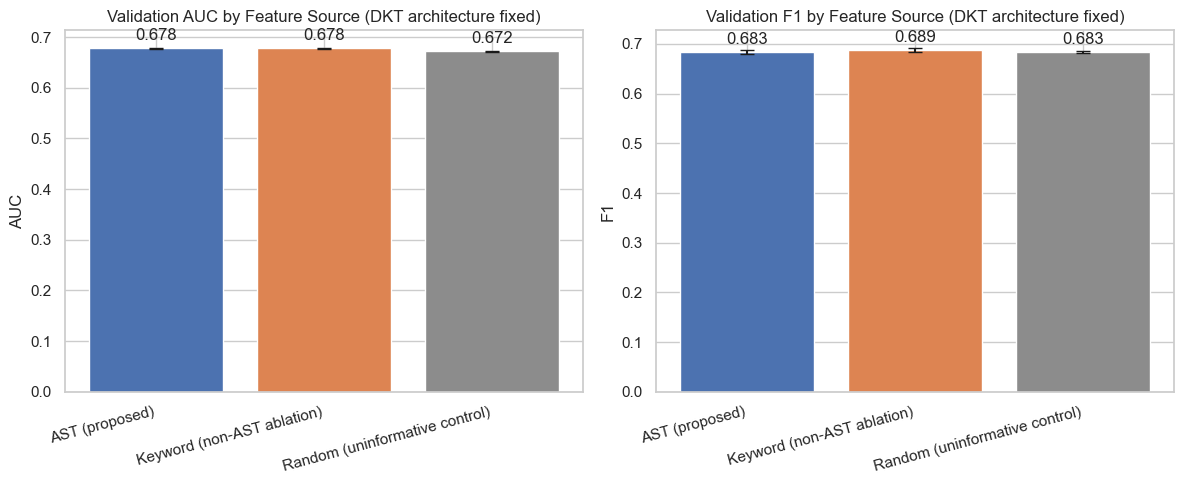


Paired t-test (per-fold AUC), AST vs. Keyword: t=-2.104, p=0.1031
Paired t-test (per-fold AUC), Keyword vs. Random: t=87.281, p=0.0000


In [4]:
# ==========================================================
# SUMMARY TABLE + FIGURE FOR THE REBUTTAL / PAPER
# ==========================================================

import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

summary = (
    ablation_results_df
    .groupby("condition")[["accuracy", "auc", "precision", "recall", "f1"]]
    .agg(["mean", "std"])
)

print("\n" + "=" * 70)
print(" ABLATION SUMMARY (mean ± std across 5 folds)")
print("=" * 70)
print(summary)

summary.to_csv("ablation_summary.csv")

# Order conditions for readability: proposed -> ablation -> control
condition_order = ["AST (proposed)", "Keyword (non-AST ablation)", "Random (uninformative control)"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, metric in zip(axes, ["auc", "f1"]):
    means = [ablation_results_df[ablation_results_df["condition"] == c][metric].mean() for c in condition_order]
    stds = [ablation_results_df[ablation_results_df["condition"] == c][metric].std() for c in condition_order]

    bars = ax.bar(condition_order, means, yerr=stds, capsize=5,
                   color=["#4C72B0", "#DD8452", "#8C8C8C"])
    ax.set_title(f"Validation {metric.upper()} by Feature Source (DKT architecture fixed)")
    ax.set_ylabel(metric.upper())
    ax.set_xticklabels(condition_order, rotation=15, ha="right")

    for bar, mean in zip(bars, means):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
                f"{mean:.3f}", ha="center", va="bottom")

plt.tight_layout()
plt.savefig("ablation_feature_source.png", dpi=200)
plt.show()

# ==========================================================
# STATISTICAL CHECK: paired comparison across folds
# (same splits per fold across conditions -> paired test is valid)
# ==========================================================

from scipy import stats

ast_auc = ablation_results_df[ablation_results_df["condition"] == "AST (proposed)"].sort_values("fold")["auc"].values
kw_auc = ablation_results_df[ablation_results_df["condition"] == "Keyword (non-AST ablation)"].sort_values("fold")["auc"].values
rand_auc = ablation_results_df[ablation_results_df["condition"] == "Random (uninformative control)"].sort_values("fold")["auc"].values

t_ast_kw, p_ast_kw = stats.ttest_rel(ast_auc, kw_auc)
t_kw_rand, p_kw_rand = stats.ttest_rel(kw_auc, rand_auc)

print("\nPaired t-test (per-fold AUC), AST vs. Keyword: "
      f"t={t_ast_kw:.3f}, p={p_ast_kw:.4f}")
print("Paired t-test (per-fold AUC), Keyword vs. Random: "
      f"t={t_kw_rand:.3f}, p={p_kw_rand:.4f}")
